In [ ]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT)


In [1]:
# Week 1 — Pipeline Validation
# Reproduce published transmon and fluxonium values so the simulation pipeline is trustworthy before generating new results. 
# Checks: (1) transmon frequency & anharmonicity vs theory, (2) fluxonium sweet spot at Φ/Φ₀=0.5, (3–4) coherence in µs with T2 ≤ 2·T1.

In [2]:
# Cell 1 — Transmon: check frequency & anharmonicity against theory
import scqubits as scq, numpy as np
t = scq.Transmon(EJ=15.0, EC=0.3, ng=0.0, ncut=30)
e = t.eigenvals(evals_count=5)
print("freq", round(e[1]-e[0],3), "anharm", round((e[2]-e[1])-(e[1]-e[0]),3))

freq 5.683 anharm -0.345


Spectral data:   0%|          | 0/150 [00:00<?, ?it/s]

findfont: Failed to find font weight 500, now using 400.


(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='$\\Phi_{ext}/\\Phi_0$', ylabel='energy [GHz]'>)

findfont: Failed to find font weight 500, now using 400.


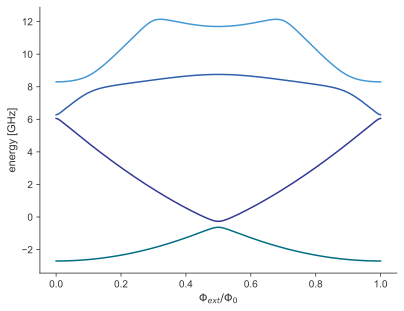

In [3]:
# Cell 2 — Fluxonium: energy levels vs flux (see the sweet spot)
fx = scq.Fluxonium(EJ=8.9, EC=2.5, EL=0.5, flux=0.5, cutoff=110)
fx.plot_evals_vs_paramvals('flux', np.linspace(0,1,150), evals_count=4)

In [4]:
# Cell 3 — Transmon coherence (values in microseconds)
T1  = t.t1_capacitive(i=1, j=0, Q_cap=1e6)
Tpn = t.tphi_1_over_f_ng(A_noise=1e-4, i=0, j=1)
T2  = 1 / (1/(2*T1) + 1/Tpn)
print("Transmon   T1", round(T1*1e-3, 1), "us  T2", round(T2*1e-3, 1),
      "us  2T1", round(2*T1*1e-3, 1), "us")

Transmon   T1 28.0 us  T2 56.0 us  2T1 56.0 us


See documentation for details.
This warning can be disabled by executing:
scqubits.settings.T1_DEFAULT_WARNING=False

 /Users/ishita/miniconda3/envs/qubits/lib/python3.11/site-packages/scqubits/core/noise.py: 1213

In [5]:
# Cell 4 — Fluxonium coherence (values in microseconds)
T1_f  = fx.t1_capacitive(i=1, j=0, Q_cap=1e6)
Tpf_f = fx.tphi_1_over_f_flux(A_noise=1e-6, i=0, j=1)
T2_f  = 1 / (1/(2*T1_f) + 1/Tpf_f)
print("Fluxonium  T1", round(T1_f*1e-3, 1), "us  T2", round(T2_f*1e-3, 1),
      "us  2T1", round(2*T1_f*1e-3, 1), "us")

Fluxonium  T1 771.1 us  T2 1542.2 us  2T1 1542.2 us
